# Handwritten Digit Recognition using SVM (MNIST)

A beginner-friendly notebook to train, measure, evaluate, and save a **Support Vector Machine (SVM)** model on the MNIST dataset.

### Pipeline Overview:
1. **Load Data**: Read `mnist_train.csv` and `mnist_test.csv`.
2. **Explore & Preprocess**: Separate features ($X$) from labels ($y$) and normalize pixels to $[0.0, 1.0]$.
3. **Train Model & Track Time**: Train an SVM classifier using `SVC()` and measure elapsed training time with `time`.
4. **Evaluate Performance**: Compute test accuracy, classification report, and confusion matrix.
5. **Save the Model**: Persist the trained model to disk using `joblib`.

In [1]:
# Step 1: Import required libraries
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. Load the Dataset
We load the training and testing CSV files directly using `pandas`.

In [2]:
# Load CSV files
train_data = pd.read_csv('mnist_train.csv')
test_data = pd.read_csv('mnist_test.csv')

print(f"Training data shape: {train_data.shape}")
print(f"Testing data shape:  {test_data.shape}")

# Preview the first 5 rows
train_data.head()

Training data shape: (60000, 785)
Testing data shape:  (10000, 785)


,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 2. Separate Features ($X$) and Labels ($y$)
- **`y` (Target)**: The digit label (0 to 9).
- **`X` (Features)**: The 784 pixel values representing the flattened $28 \times 28$ image.

In [3]:
# Separate y (labels) and X (pixel features)
y_train = train_data['label'].values
X_train = train_data.drop(columns=['label']).values

y_test = test_data['label'].values
X_test = test_data.drop(columns=['label']).values

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_train shape: (60000, 784)
y_train shape: (60000,)
X_test shape:  (10000, 784)
y_test shape:  (10000,)


### Visualizing a Few Digits
Let's reshape a few 784-length feature rows back into $28 \times 28$ 2D arrays to see the actual handwritten images.

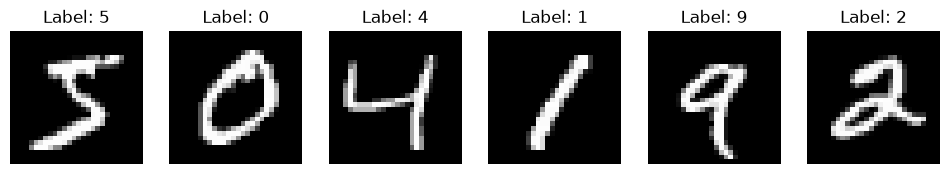

In [4]:
# Display first 6 digits
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i, ax in enumerate(axes):
    image = X_train[i].reshape(28, 28)
    ax.imshow(image, cmap='gray')
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis('off')

plt.show()

## 3. Preprocessing: Normalization
Raw pixel intensities range from `0` to `255`.

We divide by `255.0` to rescale all values to the range $[0.0, 1.0]$.
> **Why?** SVM relies on Euclidean distance between data points. When all features are normalized between 0 and 1, the optimizer converges much faster and achieves higher accuracy.

In [5]:
# Normalize pixel values from [0, 255] to [0.0, 1.0]
X_train = X_train / 255.0
X_test = X_test / 255.0


# SUBSET_SIZE = 10000
# X_train_sub = X_train[:SUBSET_SIZE]
# y_train_sub = y_train[:SUBSET_SIZE]


## 4. Train the SVM Model (with Time Tracking)
We use `scikit-learn`'s `SVC` with an **RBF kernel** (`C=5.0`).
- We track training time with Python's built-in `time` module so we know exactly how long training took.

In [6]:
# Initialize the SVM classifier
model = SVC(kernel='rbf', C=5.0)

print("Training the SVM model...")
start_time = time.time()

# Train the model
model.fit(X_train, y_train)

end_time = time.time()
training_duration = end_time - start_time

print(f"Training finished in {training_duration}")

Training the SVM model...
Training finished in 375.09175086021423


## 5. Model Evaluation
We evaluate the trained model on our unseen test dataset (`X_test`).

In [7]:
# Predict on the test set
start_pred = time.time()
y_pred = model.predict(X_test)
pred_duration = time.time() - start_pred

# Calculate and display test accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Prediction on test images took: {pred_duration:.2f} seconds")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Precision, Recall, and F1-score for each digit (0 to 9)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

Prediction on test images took: 143.12 seconds
Test Accuracy: 98.41%

Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.98      0.99      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.99      0.98      0.98       892
           6       0.99      0.99      0.99       958
           7       0.98      0.98      0.98      1028
           8       0.98      0.98      0.98       974
           9       0.98      0.97      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



### Confusion Matrix Heatmap
A heatmap showing which digits were classified correctly (diagonal) and which were confused with others (off-diagonal).

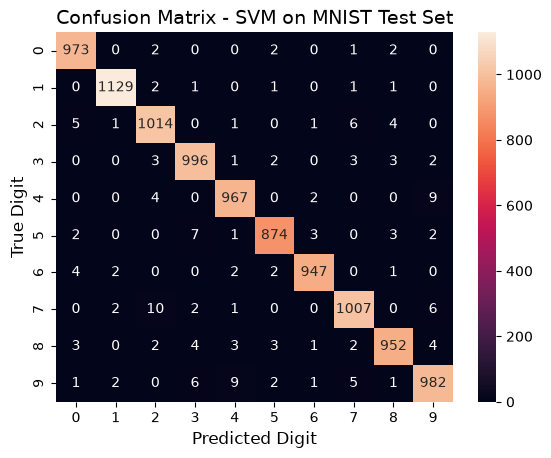

In [8]:
# Compute and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - SVM on MNIST Test Set", fontsize=14)
plt.xlabel("Predicted Digit", fontsize=12)
plt.ylabel("True Digit", fontsize=12)
plt.show()

### Visualizing Sample Predictions
Let's inspect the first 6 test samples with their true and predicted labels (green if correct, red if incorrect).

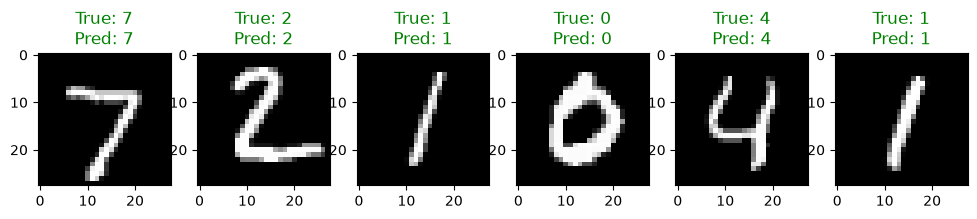

In [9]:
# Display 6 test images with predictions
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i, ax in enumerate(axes):
    img = X_test[i].reshape(28, 28)
    true_digit = y_test[i]
    pred_digit = y_pred[i]
    
    if true_digit == pred_digit :
        color = 'green'
    else:
        color= 'red'
    
    ax.imshow(img,cmap='gray')
    ax.set_title(f"True: {true_digit}\nPred: {pred_digit}", color=color, fontsize=12)

plt.show()

## 6. Saving and Reloading the Model with `joblib`
To use the trained model later without retraining, we save it to disk using `joblib.dump()`. We can reload it anytime using `joblib.load()`.

In [10]:
# Save the trained model to a file
model_filename = 'svm_mnist_model.joblib'
joblib.dump(model, model_filename)
print(f"Model successfully saved as: {model_filename}")

# Test reloading the model
loaded_model = joblib.load(model_filename)
sample_prediction = loaded_model.predict(X_test[:1])
print(f"Reloaded model prediction for first test image: {sample_prediction[0]} (Actual: {y_test[0]})")

Model successfully saved as: svm_mnist_model.joblib
Reloaded model prediction for first test image: 7 (Actual: 7)
